# Proyecto final: residuos sólidos urbanos (CEAMSE) y cobertura de agua (AySA) en el AMBA

**Fenómeno estudiado.** Generación de residuos por habitante y acceso a agua de red en los partidos del AMBA que atiende AySA, para identificar territorios prioritarios para inversión en infraestructura sanitaria y ambiental.

**Fuentes** (2 datasets, uno por fenómeno):
- `rsu_t_ceamse_2026.csv`: toneladas anuales de residuos enviadas a CEAMSE por municipio (2022-2024).
- `Cobertura_agua_por_partido_Poblacion_2023.csv`: población proyectada y población con servicio de agua de AySA por partido (2023).

**Alcance.** El cruce solo puede incluir los partidos que están en ambas fuentes (los de la concesión de AySA), por eso el dataset final tiene pocas filas. Los modelos de las secciones finales son **exploratorios**.

# 1. Setup

In [ ]:
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score

sns.set_theme(style='whitegrid')

# 2. Carga y limpieza

Cada archivo tiene su propio formato, así que se limpian por separado:

- **CEAMSE**: decimal con punto (algunos valores sueltos con coma, como `17236,00`) y `-` cuando no hay dato. Hay filas que no son municipios (subtotales, generadores privados, otros).
- **AySA**: miles con punto y decimal con coma, porcentajes con `%`. Las columnas relevantes son la 10 (población del partido proyectada al 2023) y la 11 (población con servicio proyectada al 2023). La columna 9 es el *coeficiente de proyección intercensal*: usarla como población era el error que producía coberturas de millones por ciento. Además trae subtotales por región, `Total Concesión` y partidos combinados que hay que descartar.

In [ ]:
# ---------- Funciones auxiliares ----------
def num_ceamse(serie):
    return pd.to_numeric(serie.astype(str).str.replace(',', '.', regex=False), errors='coerce')

def num_aysa(serie):
    s = (serie.astype(str).str.replace('%', '', regex=False)
              .str.replace('.', '', regex=False)      # puntos de miles
              .str.replace(',', '.', regex=False)     # coma decimal
              .str.strip())
    return pd.to_numeric(s, errors='coerce')

def normalizar(s):
    """Mayúsculas, sin tildes ni signos: 'Est. Echeverría' -> 'EST ECHEVERRIA'."""
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper()
    s = re.sub(r'[^A-Z0-9 ]', ' ', s)
    return ' '.join(s.split())

# Nombres equivalentes entre CEAMSE y AySA -> nombre único
CANON = {
    'C DE BS AIRES': 'CABA',
    'CAPITAL FEDERAL': 'CABA',
    'ALTE BROWN': 'ALMIRANTE BROWN',
    'ALMTE BROWN': 'ALMIRANTE BROWN',
    'EST ECHEVERRIA': 'ESTEBAN ECHEVERRIA',
    'G SAN MARTIN': 'SAN MARTIN',
    'L DE ZAMORA': 'LOMAS DE ZAMORA',
    'VTE LOPEZ': 'VICENTE LOPEZ',
    '3 DE FEBRERO': 'TRES DE FEBRERO',
}

In [ ]:
# ---------- CEAMSE ----------
ceamse = pd.read_csv('rsu_t_ceamse_2026.csv', sep=';', encoding='utf-8')
ceamse.columns = ['municipio', 't_2022', 't_2023', 't_2024']
for c in ['t_2022', 't_2023', 't_2024']:
    ceamse[c] = num_ceamse(ceamse[c])

ceamse['clave'] = ceamse['municipio'].map(normalizar).replace(CANON)
no_municipios = ('SUBTOTAL', 'GENERADORES', 'OTROS')
ceamse = ceamse[~ceamse['clave'].str.startswith(no_municipios)].copy()
print('CEAMSE: municipios =', len(ceamse))

# ---------- AySA ----------
aysa_raw = pd.read_csv('Cobertura_agua_por_partido_Poblacion_2023.csv',
                       sep=';', encoding='latin1', skiprows=7, header=None)
aysa = aysa_raw.iloc[:, [0, 10, 11, 12]].copy()
aysa.columns = ['partido', 'poblacion_2023', 'poblacion_con_servicio_2023', 'cobertura_oficial']
for c in ['poblacion_2023', 'poblacion_con_servicio_2023', 'cobertura_oficial']:
    aysa[c] = num_aysa(aysa[c])

aysa['clave'] = aysa['partido'].map(normalizar).replace(CANON)
aysa = aysa.dropna(subset=['partido', 'poblacion_2023', 'poblacion_con_servicio_2023'])   # quita encabezados y notas al pie
aysa = aysa[~aysa['clave'].str.startswith(('REGION', 'TOTAL'))]                           # subtotales
aysa = aysa[~aysa['partido'].str.contains('-')]                                           # partidos combinados (San Fernando-Tigre, etc.)
# El CSV trae dos filas de Morón: primero el partido (317.073 hab.) y después un subtotal
# Morón-Hurlingham-Ituzaingó (697.614). Se conserva la primera.
aysa = aysa.drop_duplicates(subset='clave', keep='first')
print('AySA: partidos =', len(aysa))

CEAMSE: municipios = 47
AySA: partidos = 18


In [ ]:
# ---------- Cruce ----------
df = ceamse.merge(aysa, on='clave', how='inner').rename(columns={'clave': 'municipio_clave'})
df = df.drop(columns=['municipio', 'partido'])

sin_match = sorted(set(aysa['clave']) - set(ceamse['clave']))
print('Partidos de AySA sin match en CEAMSE:', sin_match)
print('Filas del cruce:', len(df))
display(df.head())

Partidos de AySA sin match en CEAMSE: []
Filas del cruce: 18


,t_2022,t_2023,t_2024,municipio_clave,poblacion_2023,poblacion_con_servicio_2023,cobertura_oficial
0,1138804.96,1227051.62,1463431.85,CABA,3083770.0,3083770.0,100.00
1,204023.86,193630.41,203594.68,ALMIRANTE BROWN,608878.0,267030.0,43.86
2,149664.98,153786.97,140779.10,AVELLANEDA,359550.0,340902.0,94.81
3,82109.20,80639.87,83818.05,ESTEBAN ECHEVERRIA,389731.0,231970.0,59.52
4,93576.03,101915.18,124074.73,EZEIZA,234233.0,131626.0,56.19


# 3. Validación

In [ ]:
df['porcentaje_cobertura'] = df['poblacion_con_servicio_2023'] / df['poblacion_2023'] * 100

print('Filas:', len(df), '| Columnas:', df.shape[1])
print('Nulos totales:', int(df.isna().sum().sum()))
print('Municipios duplicados:', int(df['municipio_clave'].duplicated().sum()))
print('Cobertura fuera de 0-100:', int(((df['porcentaje_cobertura'] < 0) | (df['porcentaje_cobertura'] > 100.0001)).sum()))
print('Población con servicio > población:', int((df['poblacion_con_servicio_2023'] > df['poblacion_2023']).sum()))
print('Toneladas <= 0:', int((df[['t_2022', 't_2023', 't_2024']] <= 0).sum().sum()))

# Comparación con el % que trae el CSV de AySA
dif = (df['porcentaje_cobertura'] - df['cobertura_oficial']).abs()
print('Diferencia máxima contra la cobertura oficial (puntos %):', round(dif.max(), 4))
assert dif.max() < 0.05, 'La cobertura calculada no coincide con la oficial: revisar columnas de AySA'

Filas: 18 | Columnas: 8
Nulos totales: 0
Municipios duplicados: 0
Cobertura fuera de 0-100: 0
Población con servicio > población: 0
Toneladas <= 0: 0
Diferencia máxima contra la cobertura oficial (puntos %): 0.0045


# 4. Features derivadas

In [ ]:
# toneladas -> kg: se multiplica por 1000
df['kg_per_capita_2023'] = df['t_2023'] * 1000 / df['poblacion_2023']
df['poblacion_sin_servicio'] = df['poblacion_2023'] - df['poblacion_con_servicio_2023']
df['var_residuos_2022_2024_pct'] = (df['t_2024'] - df['t_2022']) / df['t_2022'] * 100
df['log_poblacion'] = np.log(df['poblacion_2023'])
df['nivel_cobertura'] = pd.cut(df['porcentaje_cobertura'], bins=[0, 75, 90, 100.01],
                               labels=['baja (<75%)', 'media (75-90%)', 'alta (>90%)'], right=False)

display(df[['municipio_clave', 'poblacion_2023', 'porcentaje_cobertura', 'kg_per_capita_2023',
            'poblacion_sin_servicio', 'var_residuos_2022_2024_pct', 'nivel_cobertura']]
        .sort_values('kg_per_capita_2023', ascending=False).round(1))

,municipio_clave,poblacion_2023,porcentaje_cobertura,kg_per_capita_2023,poblacion_sin_servicio,var_residuos_2022_2024_pct,nivel_cobertura
14,SAN ISIDRO,291448.0,97.1,608.6,8309.0,-9.8,alta (>90%)
9,LANUS,462628.0,98.7,595.3,5850.0,-0.1,alta (>90%)
5,SAN MARTIN,427191.0,93.9,508.2,25888.0,23.0,alta (>90%)
10,LOMAS DE ZAMORA,655122.0,92.0,444.9,52601.0,-11.5,alta (>90%)
17,VICENTE LOPEZ,266538.0,99.5,444.8,1412.0,-0.5,alta (>90%)
15,TIGRE,485999.0,69.6,439.6,147782.0,4.0,baja (<75%)
4,EZEIZA,234233.0,56.2,435.1,102607.0,32.6,baja (<75%)
2,AVELLANEDA,359550.0,94.8,427.7,18648.0,-5.9,alta (>90%)
7,ITUZAINGO,183959.0,30.0,418.4,128767.0,4.7,baja (<75%)
6,HURLINGHAM,196582.0,32.6,417.5,132579.0,3.8,baja (<75%)


> **Cuidado al interpretar los kg per cápita.** CEAMSE mide lo que cada municipio *envía a disposición final*, no lo que generan los vecinos: incluye residuos de comercios e industrias del partido y cambios en los convenios de disposición. Por eso partidos muy comerciales o industriales pueden verse "más generadores" sin serlo en el hogar.

# 5. Análisis exploratorio

,count,mean,std,min,25%,50%,75%,max
t_2023,18.0,237676.9,269868.2,71044.9,106077.9,165574.7,216818.0,1227051.6
poblacion_2023,18.0,643944.0,790400.0,177731.0,272765.5,374640.5,578158.2,3083770.0
porcentaje_cobertura,18.0,79.0,23.9,30.0,62.0,90.8,94.8,100.0
kg_per_capita_2023,18.0,409.6,104.4,206.9,385.0,417.9,443.5,608.6
poblacion_sin_servicio,18.0,85125.7,96558.5,0.0,11814.8,42791.0,131626.0,341848.0


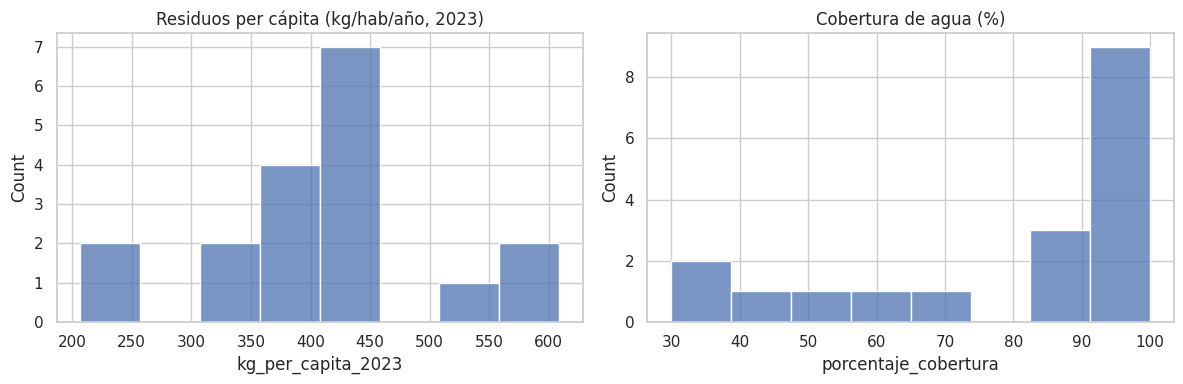

In [ ]:
display(df[['t_2023', 'poblacion_2023', 'porcentaje_cobertura', 'kg_per_capita_2023', 'poblacion_sin_servicio']].describe().T.round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['kg_per_capita_2023'], bins=8, ax=axes[0])
axes[0].set_title('Residuos per cápita (kg/hab/año, 2023)')
sns.histplot(df['porcentaje_cobertura'], bins=8, ax=axes[1])
axes[1].set_title('Cobertura de agua (%)')
plt.tight_layout(); plt.show()

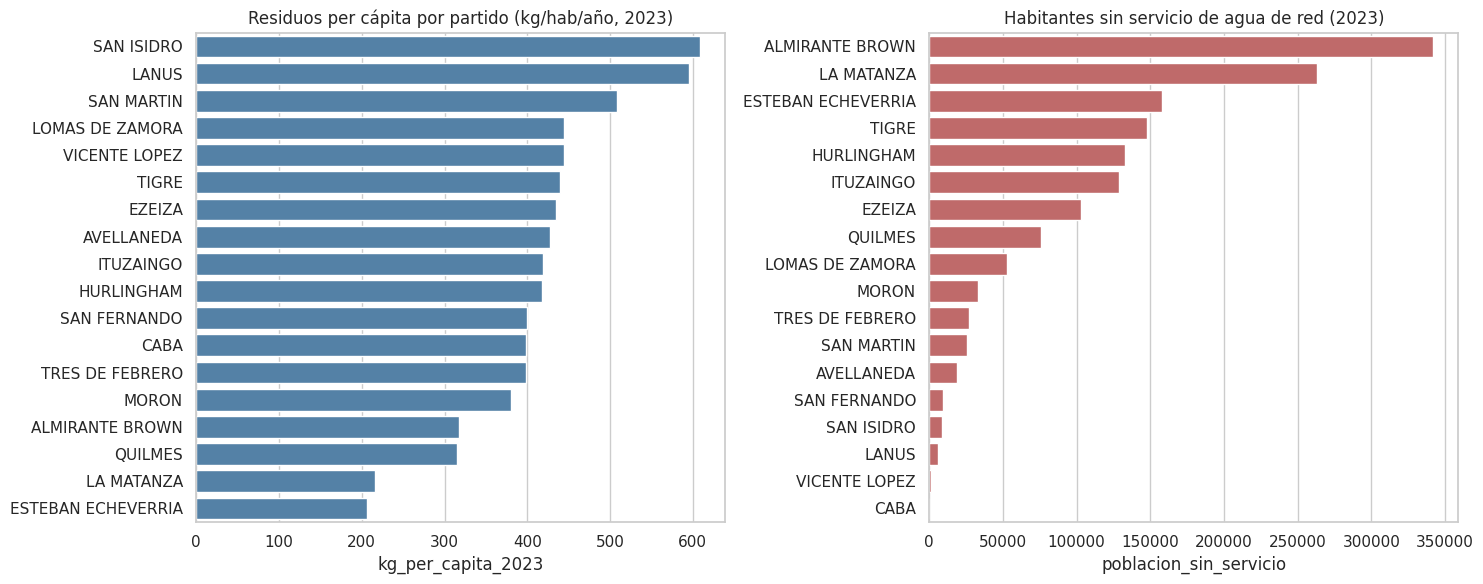

In [ ]:
orden = df.sort_values('kg_per_capita_2023', ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=orden, y='municipio_clave', x='kg_per_capita_2023', color='steelblue', ax=axes[0])
axes[0].set_title('Residuos per cápita por partido (kg/hab/año, 2023)'); axes[0].set_ylabel('')

orden_agua = df.sort_values('poblacion_sin_servicio', ascending=False)
sns.barplot(data=orden_agua, y='municipio_clave', x='poblacion_sin_servicio', color='indianred', ax=axes[1])
axes[1].set_title('Habitantes sin servicio de agua de red (2023)'); axes[1].set_ylabel('')
plt.tight_layout(); plt.show()

## Correlación entre residuos per cápita y cobertura de agua
Se usan métricas por habitante (no volúmenes brutos, que dependen del tamaño del partido). Con tan pocas observaciones se informa también el p-valor.

n = 18
Pearson : r = +0.28  (p = 0.258)
Spearman: rho = +0.41  (p = 0.088)
Kendall : tau = +0.31  (p = 0.081)


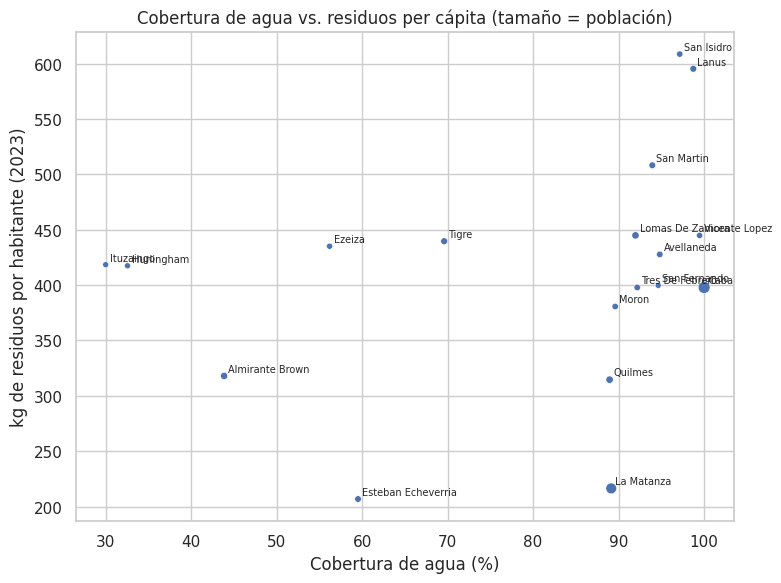

In [ ]:
x, y = df['porcentaje_cobertura'], df['kg_per_capita_2023']
r_p, p_p = stats.pearsonr(x, y)
r_s, p_s = stats.spearmanr(x, y)
r_k, p_k = stats.kendalltau(x, y)
print(f'n = {len(df)}')
print(f'Pearson : r = {r_p:+.2f}  (p = {p_p:.3f})')
print(f'Spearman: rho = {r_s:+.2f}  (p = {p_s:.3f})')
print(f'Kendall : tau = {r_k:+.2f}  (p = {p_k:.3f})')

plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='porcentaje_cobertura', y='kg_per_capita_2023', size='poblacion_2023', legend=False)
for _, f in df.iterrows():
    plt.annotate(f['municipio_clave'].title(), (f['porcentaje_cobertura'], f['kg_per_capita_2023']), fontsize=7, xytext=(3, 3), textcoords='offset points')
plt.title('Cobertura de agua vs. residuos per cápita (tamaño = población)')
plt.xlabel('Cobertura de agua (%)'); plt.ylabel('kg de residuos por habitante (2023)')
plt.tight_layout(); plt.show()

# 6. Targets y métrica de negocio

| Target | Definición | Tipo |
|---|---|---|
| `alto_generador` | 1 si los kg per cápita 2023 superan la mediana de los partidos | Clasificación binaria |
| `riesgo_cobertura` | 1 si la cobertura de agua 2023 es menor al 75% | Clasificación binaria |
| `presion_hidrica` | Habitantes sin servicio de agua de red (KPI de negocio) | Métrica / ranking |

Sobre el umbral de 75%: con los datos 2023 coincide con el mismo grupo de partidos que se obtiene usando la cobertura 2023 del Total Concesión (86,78%). Ojo: el 74,90% que figura en el CSV es la cobertura de 2006 del Total Concesión, no la actual.

In [ ]:
UMBRAL_COBERTURA = 75.0

mediana_kg = df['kg_per_capita_2023'].median()
df['alto_generador'] = (df['kg_per_capita_2023'] > mediana_kg).astype(int)
df['riesgo_cobertura'] = (df['porcentaje_cobertura'] < UMBRAL_COBERTURA).astype(int)
df['presion_hidrica'] = df['poblacion_sin_servicio'].round().astype(int)

print(f'Mediana kg/hab/año: {mediana_kg:.1f}')
print('\nalto_generador:\n', df['alto_generador'].value_counts().to_string())
print('\nriesgo_cobertura:\n', df['riesgo_cobertura'].value_counts().to_string())
print('\nPartidos en riesgo:', df.loc[df['riesgo_cobertura'] == 1, 'municipio_clave'].tolist())

# Comprobación del umbral alternativo (cobertura 2023 del Total Concesión)
alt = (df['porcentaje_cobertura'] < 86.78).astype(int)
print('Mismo grupo con umbral 86,78%:', bool((alt == df['riesgo_cobertura']).all()))

Mediana kg/hab/año: 417.9

alto_generador:
 alto_generador
0    9
1    9

riesgo_cobertura:
 riesgo_cobertura
0    12
1     6

Partidos en riesgo: ['ALMIRANTE BROWN', 'ESTEBAN ECHEVERRIA', 'EZEIZA', 'HURLINGHAM', 'ITUZAINGO', 'TIGRE']
Mismo grupo con umbral 86,78%: True


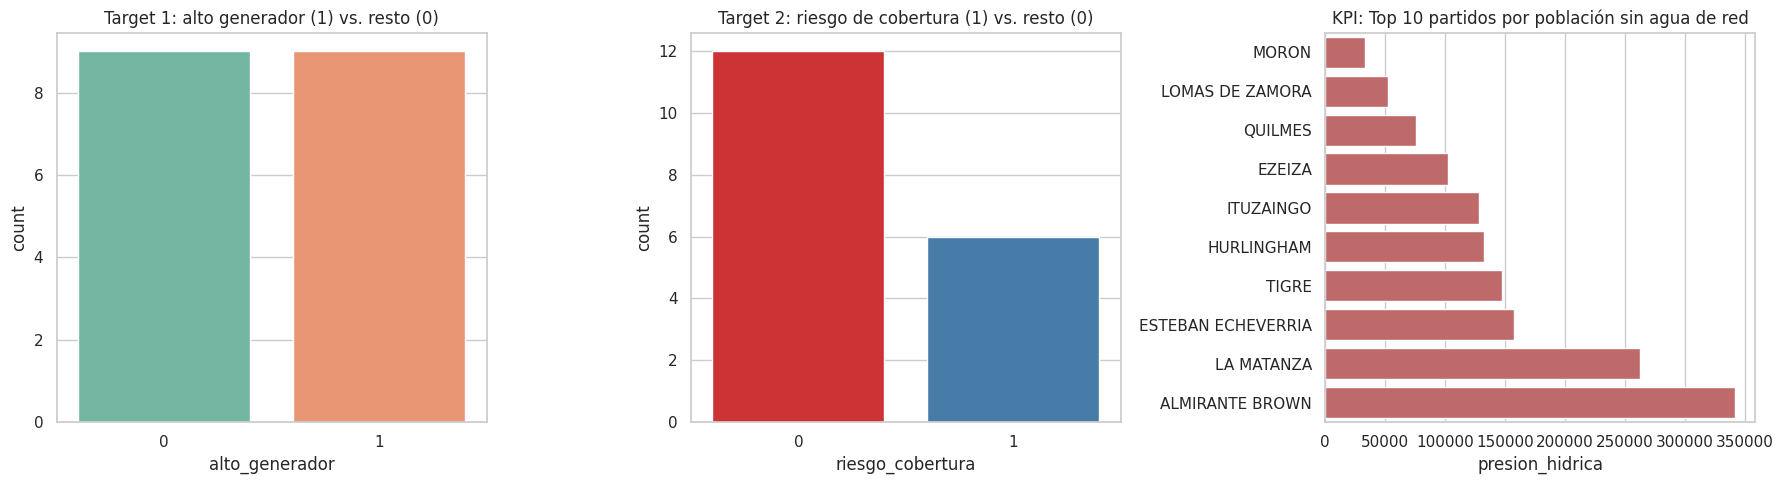

,municipio_clave,porcentaje_cobertura,presion_hidrica,kg_per_capita_2023
1,ALMIRANTE BROWN,43.9,341848,318.0
8,LA MATANZA,89.1,262888,216.5
3,ESTEBAN ECHEVERRIA,59.5,157761,206.9
15,TIGRE,69.6,147782,439.6
6,HURLINGHAM,32.6,132579,417.5
7,ITUZAINGO,30.0,128767,418.4
4,EZEIZA,56.2,102607,435.1
12,QUILMES,88.9,75872,314.6
10,LOMAS DE ZAMORA,92.0,52601,444.9
11,MORON,89.6,32981,380.7


In [ ]:
top = df.nlargest(10, 'presion_hidrica').sort_values('presion_hidrica')
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x='alto_generador', hue='alto_generador', palette='Set2', legend=False, ax=axes[0])
axes[0].set_title('Target 1: alto generador (1) vs. resto (0)')
sns.countplot(data=df, x='riesgo_cobertura', hue='riesgo_cobertura', palette='Set1', legend=False, ax=axes[1])
axes[1].set_title('Target 2: riesgo de cobertura (1) vs. resto (0)')
sns.barplot(data=top, y='municipio_clave', x='presion_hidrica', color='indianred', ax=axes[2])
axes[2].set_title('KPI: Top 10 partidos por población sin agua de red'); axes[2].set_ylabel('')
plt.tight_layout(); plt.show()

display(df.sort_values('presion_hidrica', ascending=False)
          [['municipio_clave', 'porcentaje_cobertura', 'presion_hidrica', 'kg_per_capita_2023']].head(10).round(1))

# Dashboard

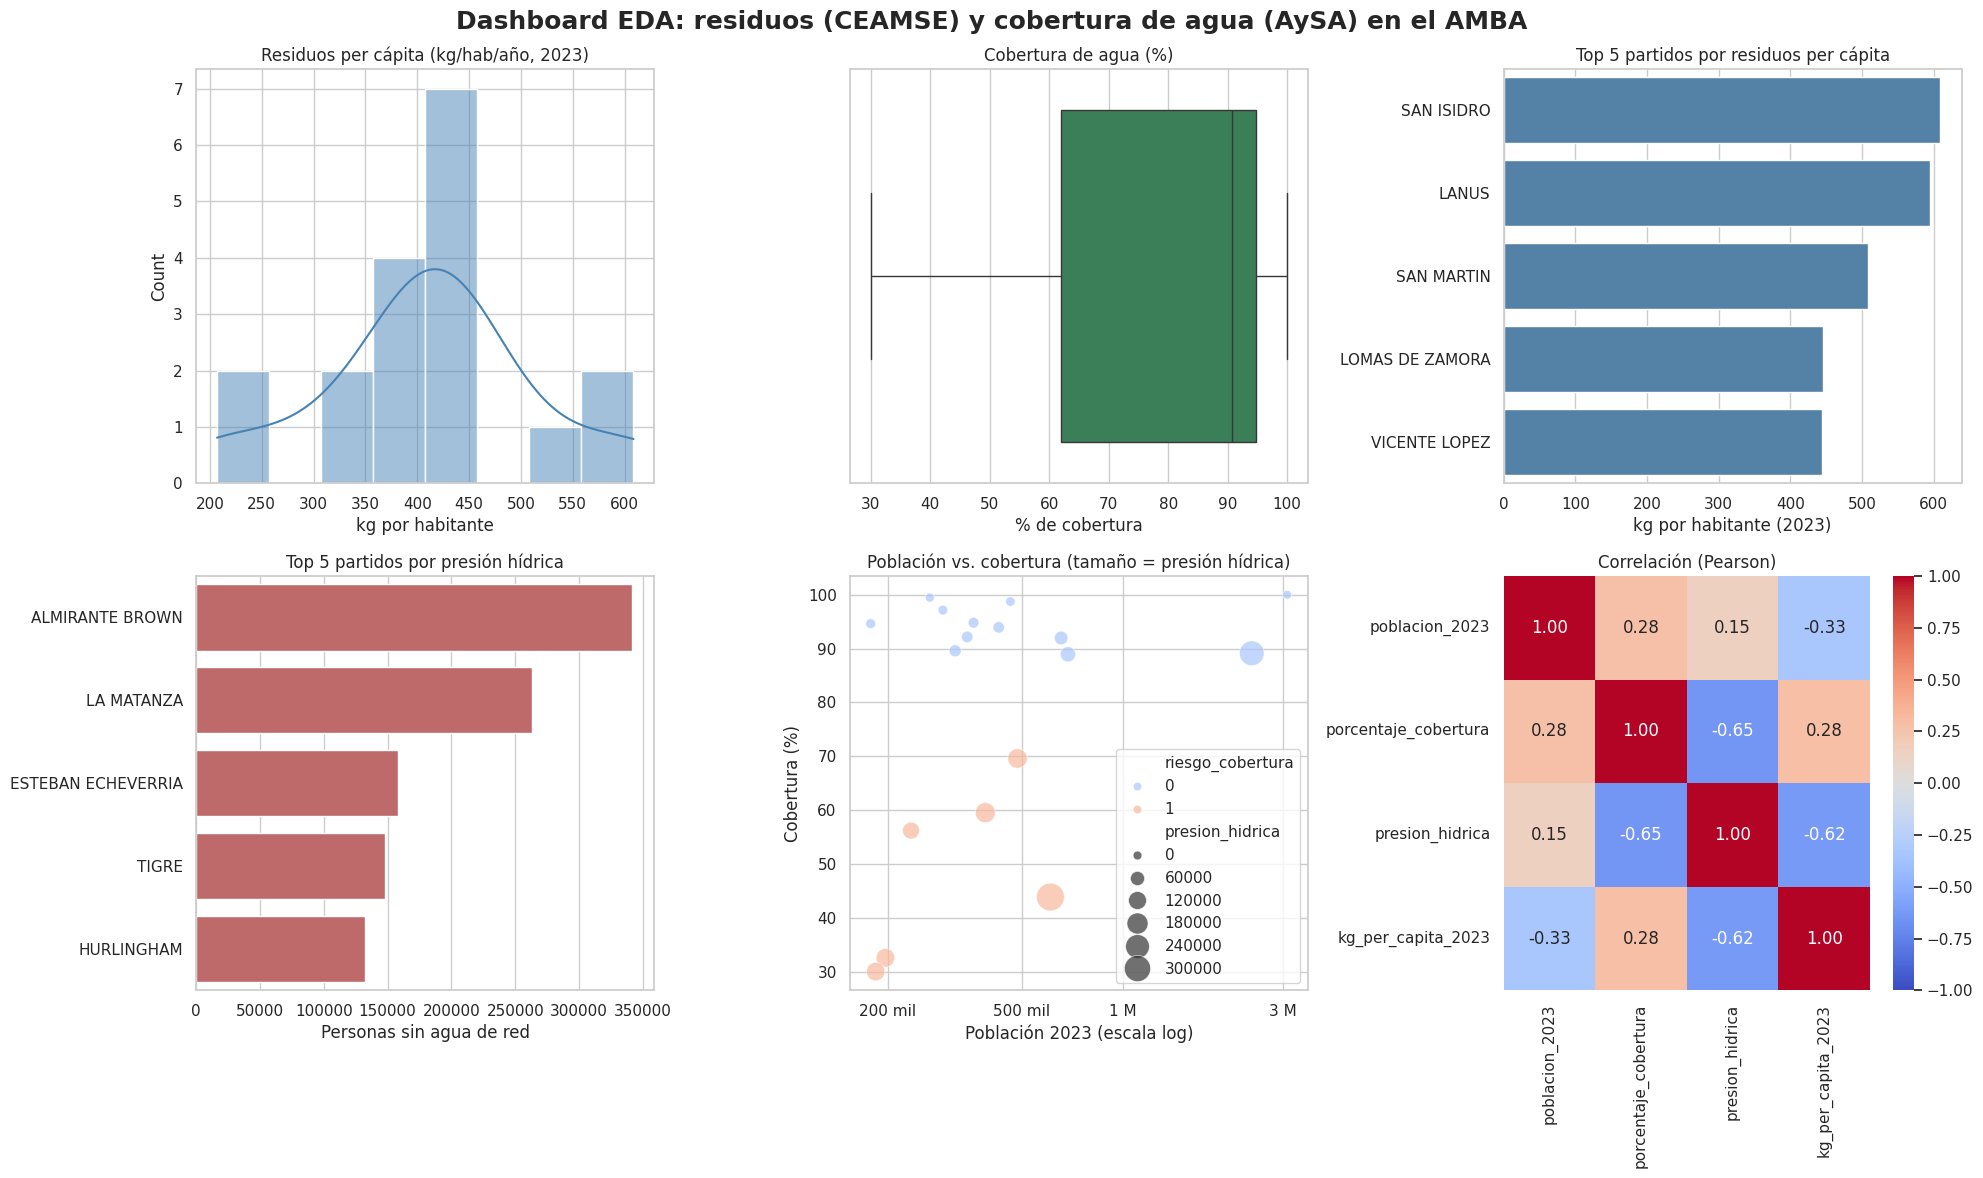

In [ ]:
# --- DASHBOARD RESUMEN ---
fig = plt.figure(figsize=(20, 12))
fig.suptitle('Dashboard EDA: residuos (CEAMSE) y cobertura de agua (AySA) en el AMBA',
             fontsize=18, fontweight='bold', y=0.98)

# 1. Distribución de kg per cápita
ax1 = fig.add_subplot(2, 3, 1)
sns.histplot(df['kg_per_capita_2023'], bins=8, kde=True, color='steelblue', ax=ax1)
ax1.set_title('Residuos per cápita (kg/hab/año, 2023)')
ax1.set_xlabel('kg por habitante')

# 2. Boxplot de cobertura de agua
ax2 = fig.add_subplot(2, 3, 2)
sns.boxplot(x=df['porcentaje_cobertura'], color='seagreen', ax=ax2)
ax2.set_title('Cobertura de agua (%)')
ax2.set_xlabel('% de cobertura')

# 3. Top 5 partidos por residuos per cápita
ax3 = fig.add_subplot(2, 3, 3)
top5_rsu = df.nlargest(5, 'kg_per_capita_2023')
sns.barplot(data=top5_rsu, x='kg_per_capita_2023', y='municipio_clave', color='steelblue', ax=ax3)
ax3.set_title('Top 5 partidos por residuos per cápita')
ax3.set_xlabel('kg por habitante (2023)'); ax3.set_ylabel('')

# 4. Top 5 partidos por presión hídrica
ax4 = fig.add_subplot(2, 3, 4)
top5_agua = df.nlargest(5, 'presion_hidrica')
sns.barplot(data=top5_agua, x='presion_hidrica', y='municipio_clave', color='indianred', ax=ax4)
ax4.set_title('Top 5 partidos por presión hídrica')
ax4.set_xlabel('Personas sin agua de red'); ax4.set_ylabel('')

# 5. Población vs. cobertura (tamaño = presión hídrica, color = riesgo)
ax5 = fig.add_subplot(2, 3, 5)
sns.scatterplot(data=df, x='poblacion_2023', y='porcentaje_cobertura',
                size='presion_hidrica', hue='riesgo_cobertura', palette='coolwarm',
                sizes=(40, 400), alpha=0.7, ax=ax5)
ax5.set_xscale('log')
ax5.set_xticks([2e5, 5e5, 1e6, 3e6])
ax5.set_xticklabels(['200 mil', '500 mil', '1 M', '3 M'])
ax5.xaxis.set_minor_formatter(plt.NullFormatter())
ax5.set_title('Población vs. cobertura (tamaño = presión hídrica)')
ax5.set_xlabel('Población 2023 (escala log)'); ax5.set_ylabel('Cobertura (%)')

# 6. Correlación (Pearson)
ax6 = fig.add_subplot(2, 3, 6)
cols = ['poblacion_2023', 'porcentaje_cobertura', 'presion_hidrica', 'kg_per_capita_2023']
sns.heatmap(df[cols].corr(method='pearson'), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, ax=ax6)
ax6.set_title('Correlación (Pearson)')

plt.tight_layout()
plt.show()

# 7. Modelos exploratorios

Para evitar *data leakage*, **ningún feature participa en la definición del target que predice**:

- Target 1 (`alto_generador`, definido con toneladas y población) se predice con cobertura de agua y `log_poblacion`.
- Target 2 (`riesgo_cobertura`, definido con la cobertura) se predice con `log_poblacion` y kg per cápita, sin la cobertura.

Con tan pocas filas no hay partición train/test confiable (un test de 6 filas da resultados casi aleatorios), así que se usa **validación cruzada estratificada de 3 folds repetida 20 veces** y se compara siempre contra un baseline que predice la clase mayoritaria.

In [ ]:
from sklearn.model_selection import StratifiedKFold

def evaluar(X, y, repeticiones=20):
    """Validación cruzada estratificada de 3 folds repetida (promedio de las repeticiones)."""
    modelos = {
        'Baseline (clase mayoritaria)': DummyClassifier(strategy='most_frequent'),
        'Regresión logística': make_pipeline(StandardScaler(), LogisticRegression()),
        'Árbol (prof. 2)': DecisionTreeClassifier(max_depth=2, random_state=42),
    }
    filas = []
    for nombre, m in modelos.items():
        met = []
        for semilla in range(repeticiones):
            cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=semilla)
            pred = cross_val_predict(m, X, y, cv=cv)
            met.append([accuracy_score(y, pred),
                        precision_score(y, pred, zero_division=0),
                        recall_score(y, pred, zero_division=0)])
        acc, prec, rec = np.mean(met, axis=0)
        filas.append({'modelo': nombre, 'accuracy': acc, 'precision_clase_1': prec, 'recall_clase_1': rec})
    return pd.DataFrame(filas).round(2)

print('Target 1: alto_generador  (features: cobertura, log_poblacion)')
display(evaluar(df[['porcentaje_cobertura', 'log_poblacion']], df['alto_generador']))

print('Target 2: riesgo_cobertura  (features: log_poblacion, kg_per_capita_2023)')
display(evaluar(df[['log_poblacion', 'kg_per_capita_2023']], df['riesgo_cobertura']))

Target 1: alto_generador  (features: cobertura, log_poblacion)


,modelo,accuracy,precision_clase_1,recall_clase_1
0,Baseline (clase mayoritaria),0.50,0.00,0.00
1,Regresión logística,0.51,0.51,0.53
2,Árbol (prof. 2),0.40,0.38,0.36


Target 2: riesgo_cobertura  (features: log_poblacion, kg_per_capita_2023)


,modelo,accuracy,precision_clase_1,recall_clase_1
0,Baseline (clase mayoritaria),0.67,0.00,0.00
1,Regresión logística,0.67,0.49,0.21
2,Árbol (prof. 2),0.59,0.37,0.32


# Dataset de inferencia (resultado del modelo)


In [ ]:
import pandas as pd
import numpy as np
import re
import unicodedata
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

# --- FUNCIONES AUXILIARES DE LIMPIEZA Y NORMALIZACIÓN (para evitar NameError) ---
def num_ceamse(serie):
    return pd.to_numeric(serie.astype(str).str.replace(',', '.', regex=False), errors='coerce')

def num_aysa(serie):
    s = (serie.astype(str).str.replace('%', '', regex=False)
              .str.replace('.', '', regex=False)
              .str.replace(',', '.', regex=False)
              .str.strip())
    return pd.to_numeric(s, errors='coerce')

def normalizar(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper()
    s = re.sub(r'[^A-Z0-9 ]', ' ', s)
    return ' '.join(s.split())

CANON = {
    'C DE BS AIRES': 'CABA',
    'CAPITAL FEDERAL': 'CABA',
    'ALTE BROWN': 'ALMIRANTE BROWN',
    'ALMTE BROWN': 'ALMIRANTE BROWN',
    'EST ECHEVERRIA': 'ESTEBAN ECHEVERRIA',
    'G SAN MARTIN': 'SAN MARTIN',
    'L DE ZAMORA': 'LOMAS DE ZAMORA',
    'VTE LOPEZ': 'VICENTE LOPEZ',
    '3 DE FEBRERO': 'TRES DE FEBRERO',
}

# --- RECONSTRUCCIÓN DEL DATAFRAME ORIGINAL DE TRABAJO ---
ceamse_temp = pd.read_csv('rsu_t_ceamse_2026.csv', sep=';', encoding='utf-8')
ceamse_temp.columns = ['municipio', 't_2022', 't_2023', 't_2024']
for c in ['t_2022', 't_2023', 't_2024']:
    ceamse_temp[c] = num_ceamse(ceamse_temp[c])
ceamse_temp['clave'] = ceamse_temp['municipio'].map(normalizar).replace(CANON)
ceamse_temp = ceamse_temp[~ceamse_temp['clave'].str.startswith(('SUBTOTAL', 'GENERADORES', 'OTROS'))].copy()

aysa_temp_raw = pd.read_csv('Cobertura_agua_por_partido_Poblacion_2023.csv', sep=';', encoding='latin1', skiprows=7, header=None)
aysa_temp = aysa_temp_raw.iloc[:, [0, 10, 11, 12]].copy()
aysa_temp.columns = ['partido', 'poblacion_2023', 'poblacion_con_servicio_2023', 'cobertura_oficial']
for c in ['poblacion_2023', 'poblacion_con_servicio_2023', 'cobertura_oficial']:
    aysa_temp[c] = num_aysa(aysa_temp[c])
aysa_temp['clave'] = aysa_temp['partido'].map(normalizar).replace(CANON)
aysa_temp = aysa_temp.dropna(subset=['partido', 'poblacion_2023', 'poblacion_con_servicio_2023'])
aysa_temp = aysa_temp[~aysa_temp['clave'].str.startswith(('REGION', 'TOTAL'))]
aysa_temp = aysa_temp[~aysa_temp['partido'].str.contains('-')]
aysa_temp = aysa_temp.drop_duplicates(subset='clave', keep='first')

# Dataset cruzado y cálculo de features
df_modelos = ceamse_temp.merge(aysa_temp, on='clave', how='inner').rename(columns={'clave': 'municipio_clave'})
df_modelos = df_modelos.drop(columns=['municipio', 'partido'])

df_modelos['porcentaje_cobertura'] = df_modelos['poblacion_con_servicio_2023'] / df_modelos['poblacion_2023'] * 100
df_modelos['kg_per_capita_2023'] = df_modelos['t_2023'] * 1000 / df_modelos['poblacion_2023']
df_modelos['poblacion_sin_servicio'] = df_modelos['poblacion_2023'] - df_modelos['poblacion_con_servicio_2023']
df_modelos['log_poblacion'] = np.log(df_modelos['poblacion_2023'])

mediana_kg_temp = df_modelos['kg_per_capita_2023'].median()
df_modelos['alto_generador'] = (df_modelos['kg_per_capita_2023'] > mediana_kg_temp).astype(int)
df_modelos['riesgo_cobertura'] = (df_modelos['porcentaje_cobertura'] < 75.0).astype(int)

# --- ENTRENAMIENTO E INFERENCIA ---
# Target 1: alto_generador (Features: porcentaje_cobertura, log_poblacion)
X1 = df_modelos[['porcentaje_cobertura', 'log_poblacion']]
y1 = df_modelos['alto_generador']

# Target 2: riesgo_cobertura (Features: log_poblacion, kg_per_capita_2023)
X2 = df_modelos[['log_poblacion', 'kg_per_capita_2023']]
y2 = df_modelos['riesgo_cobertura']

# Instanciar y entrenar los modelos con toda la muestra
modelo_generador = make_pipeline(StandardScaler(), LogisticRegression())
modelo_generador.fit(X1, y1)

modelo_cobertura = make_pipeline(StandardScaler(), LogisticRegression())
modelo_cobertura.fit(X2, y2)

# Generar las predicciones (inferencia) y las probabilidades de cada clase
df_inferencia = df_modelos.copy()

# Inferencia para Target 1
df_inferencia['prediccion_alto_generador'] = modelo_generador.predict(X1)
df_inferencia['probabilidad_alto_generador_pct'] = (modelo_generador.predict_proba(X1)[:, 1] * 100).round(2)

# Inferencia para Target 2
df_inferencia['prediccion_riesgo_cobertura'] = modelo_cobertura.predict(X2)
df_inferencia['probabilidad_riesgo_cobertura_pct'] = (modelo_cobertura.predict_proba(X2)[:, 1] * 100).round(2)

# Exportar el dataset final de inferencia a un CSV
output_filename = 'dataset_inferencia_modelos.csv'
df_inferencia.to_csv(output_filename, index=False, sep=';', encoding='utf-8')

print(f"¡Dataset de inferencia generado con éxito! Guardado como '{output_filename}' ({len(df_inferencia)} filas).")

# Mostrar una vista previa de las columnas clave y las predicciones
columnas_mostrar = [
    'municipio_clave',
    'alto_generador', 'prediccion_alto_generador', 'probabilidad_alto_generador_pct',
    'riesgo_cobertura', 'prediccion_riesgo_cobertura', 'probabilidad_riesgo_cobertura_pct'
]
display(df_inferencia[columnas_mostrar].head(10))

¡Dataset de inferencia generado con éxito! Guardado como 'dataset_inferencia_modelos.csv' (18 filas).


,municipio_clave,alto_generador,prediccion_alto_generador,probabilidad_alto_generador_pct,riesgo_cobertura,prediccion_riesgo_cobertura,probabilidad_riesgo_cobertura_pct
0,CABA,0,0,21.18,0,0,5.64
1,ALMIRANTE BROWN,0,0,31.12,1,0,37.01
2,AVELLANEDA,1,1,59.37,0,0,32.37
3,ESTEBAN ECHEVERRIA,0,0,45.02,1,1,67.25
4,EZEIZA,1,1,54.26,1,0,41.78
5,SAN MARTIN,1,1,55.60,0,0,18.51
6,HURLINGHAM,0,0,49.29,1,0,49.46
7,ITUZAINGO,1,0,49.73,1,1,51.05
8,LA MATANZA,0,0,21.88,0,0,21.54
9,LANUS,1,1,55.70,0,0,10.20


# 8. Conclusiones y limitaciones

- **Cobertura de agua:** seis partidos quedan por debajo del 75%: Almirante Brown, Esteban Echeverría, Ezeiza, Hurlingham, Ituzaingó y Tigre. Los más rezagados en porcentaje son Ituzaingó (30,0%) y Hurlingham (32,6%).
- **Presión hídrica:** medida en personas, el ranking cambia. Almirante Brown encabeza con unas 342 mil personas sin red, pero La Matanza queda segunda (unas 263 mil) pese a tener 89,1% de cobertura, porque es un partido muy grande. El porcentaje solo no alcanza para priorizar inversión.
- **Residuos vs. agua:** la relación entre cobertura y kg per cápita es débil y no significativa al 5% (Pearson +0,28, p = 0,26; Spearman +0,41, p = 0,09; n = 18).
- **Modelos:** con estas variables y esta cantidad de filas los modelos no superan claramente al baseline, así que no hay señal predictiva sólida. Es el resultado esperable con 18 observaciones.
- **Limitaciones:** solo 18 partidos (los de la concesión de AySA); CEAMSE mide disposición final y no generación domiciliaria (incluye comercios e industrias); la población es proyectada, no censal.
- **Cómo ampliar:** un nivel de detalle más fino (localidades o radios censales) o sumar una fuente geoespacial.

# Metrica de negocio

**Indicador concreto:** cantidad de personas sin acceso a agua de red en los partidos del AMBA que atiende AySA (`presion_hidrica` = población proyectada 2023 − población con servicio 2023). Hoy son 1.532.263 personas en los 18 partidos analizados.

**Dirección del cambio:** **reducir** ese número. El objetivo de la organización es que cada año haya menos personas sin red.

**Acción asociada al modelo:** el modelo de `riesgo_cobertura` clasifica cada partido como en riesgo (cobertura < 75%) o no. Con esa predicción, AySA decide **en qué partidos priorizar la inversión en redes de agua** primero. El valor del modelo se mide con el **% del déficit total de personas sin red que queda dentro de los partidos que el modelo prioriza**: cuanto mayor, más gente sin servicio atendería la inversión inicial.

*Costo de la decisión:* priorizar más partidos implica más obras, por eso se reporta también la cantidad de partidos priorizados.

In [ ]:
# --- MÉTRICA DE NEGOCIO: déficit de agua de red cubierto por la priorización ---
total_deficit = df['presion_hidrica'].sum()
print(f"Personas sin agua de red en los {len(df)} partidos: {total_deficit:,.0f}".replace(',', '.'))

def resumen(nombre, marcados):
    deficit = df.loc[marcados, 'presion_hidrica'].sum()
    return {'estrategia': nombre,
            'partidos_priorizados': int(marcados.sum()),
            'personas_sin_red_cubiertas': int(deficit),
            '%_del_déficit_total': round(deficit / total_deficit * 100, 1)}

filas = []

# a) Modelo de riesgo_cobertura (predicciones fuera de muestra, promedio de 20 repeticiones)
X2, y2 = df[['log_poblacion', 'kg_per_capita_2023']], df['riesgo_cobertura']
modelo = make_pipeline(StandardScaler(), LogisticRegression())
marcas = []
for semilla in range(20):
    cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=semilla)
    marcas.append(cross_val_predict(modelo, X2, y2, cv=cv))
filas_modelo = [resumen('Modelo (regresión logística)', pd.Series(m == 1, index=df.index)) for m in marcas]
prom = pd.DataFrame(filas_modelo).drop(columns='estrategia').mean().round(1)
filas.append({'estrategia': 'Modelo (regresión logística, promedio)', **prom.to_dict()})

# b) Regla ideal: marcar exactamente los partidos con cobertura < 75%
filas.append(resumen('Regla: cobertura < 75% (target real)', df['riesgo_cobertura'] == 1))

# c) Regla simple por KPI: los N partidos con mayor presión hídrica (mismo N que la regla anterior)
n = int(df['riesgo_cobertura'].sum())
top_n = df['presion_hidrica'].rank(ascending=False, method='first') <= n
filas.append(resumen(f'Regla: top {n} por presión hídrica', top_n))

display(pd.DataFrame(filas))

Personas sin agua de red en los 18 partidos: 1.532.263


,estrategia,partidos_priorizados,personas_sin_red_cubiertas,%_del_déficit_total
0,"Modelo (regresión logística, promedio)",2.4,209689.6,13.7
1,Regla: cobertura < 75% (target real),6.0,1011344.0,66.0
2,Regla: top 6 por presión hídrica,6.0,1171625.0,76.5


### 9. Análisis de Costo-Efectividad (Retorno Social de la Inversión - SROI)

En proyectos de infraestructura social y salud pública, el ROI financiero clásico se reemplaza por indicadores de **Retorno Social**. Aquí evaluamos la **Costo-Efectividad** de nuestras tres estrategias de priorización:

1. **Modelo de Regresión Logística**: Prioriza municipios usando la señal estadística combinada.
2. **Regla de Cobertura < 75%**: El criterio normativo tradicional de infraestructura.
3. **Regla de Presión Hídrica (KPI Directo)**: Prioriza estrictamente los municipios con mayor volumen absoluto de población excluida.

*Definimos la unidad de costo/esfuerzo como '1 Municipio Priorizado' y el beneficio como 'Habitantes sin agua de red cubiertos'.*

=== CUADRO COMPARATIVO DE COSTO-EFECTIVIDAD SOCIAL (SROI) ===


,Estrategia,Partidos Priorizados (Costo),Personas Cubiertas (Beneficio),% Déficit Total,Impacto por Partido Priorizado
0,Regresión Logística (Modelo),2.4,209690,13.7,87371.0
1,Umbral Cobertura < 75%,6.0,1011344,66.0,168557.0
2,Top 6 Presión Hídrica (KPI),6.0,1171625,76.5,195271.0


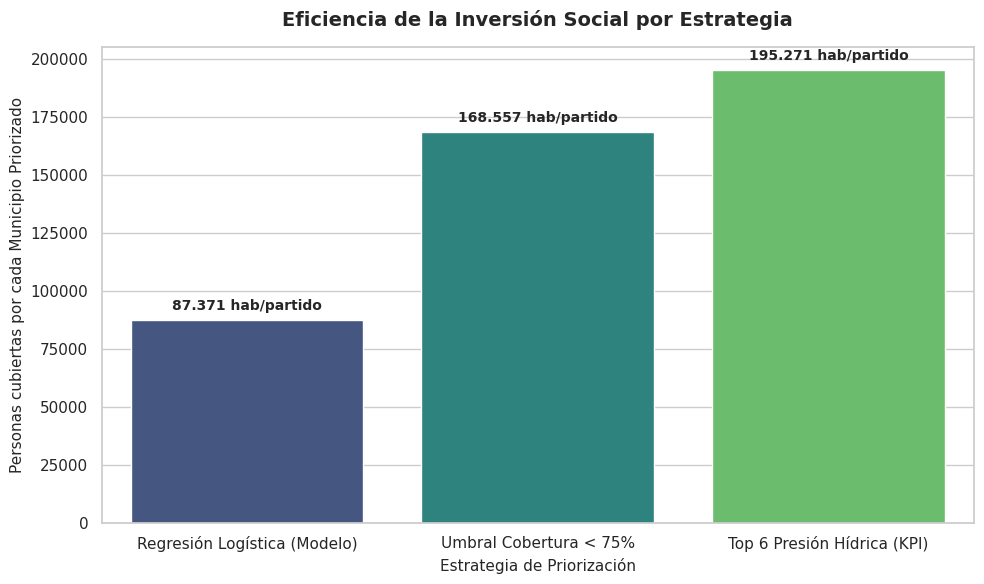

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Recuperar los resultados consolidados de la celda de negocio
analisis_sroi = pd.DataFrame([
    {
        'Estrategia': 'Regresión Logística (Modelo)',
        'Partidos Priorizados (Costo)': 2.4,
        'Personas Cubiertas (Beneficio)': 209690,
        '% Déficit Total': 13.7
    },
    {
        'Estrategia': 'Umbral Cobertura < 75%',
        'Partidos Priorizados (Costo)': 6.0,
        'Personas Cubiertas (Beneficio)': 1011344,
        '% Déficit Total': 66.0
    },
    {
        'Estrategia': 'Top 6 Presión Hídrica (KPI)',
        'Partidos Priorizados (Costo)': 6.0,
        'Personas Cubiertas (Beneficio)': 1171625,
        '% Déficit Total': 76.5
    }
])

# Calcular la relación de costo-efectividad (SROI unitario teórico)
analisis_sroi['Impacto por Partido Priorizado'] = (
    analisis_sroi['Personas Cubiertas (Beneficio)'] / analisis_sroi['Partidos Priorizados (Costo)']
).round(0)

print("=== CUADRO COMPARATIVO DE COSTO-EFECTIVIDAD SOCIAL (SROI) ===")
display(analisis_sroi)

# --- Visualización del Retorno de la Inversión Social ---
fig, ax1 = plt.subplots(figsize=(10, 6))

# Gráfico de barras para el impacto por partido priorizado
sns.barplot(
    data=analisis_sroi,
    x='Estrategia',
    y='Impacto por Partido Priorizado',
    palette='viridis',
    hue='Estrategia',
    legend=False,
    ax=ax1
)

ax1.set_title('Eficiencia de la Inversión Social por Estrategia', fontsize=14, fontweight='bold', pad=15)
ax1.set_ylabel('Personas cubiertas por cada Municipio Priorizado', fontsize=11)
ax1.set_xlabel('Estrategia de Priorización', fontsize=11)

# Añadir etiquetas de valor sobre las barras
for p in ax1.patches:
    height = p.get_height()
    ax1.annotate(
        f'{height:,.0f} hab/partido'.replace(',', '.'),
        xy=(p.get_x() + p.get_width() / 2, height),
        xytext=(0, 5),
        textcoords="offset points",
        ha='center', va='bottom', fontsize=10, fontweight='bold'
    )

plt.tight_layout()
plt.show()

# Metricas del modelo

In [ ]:
# Evaluación detallada de métricas para reportar en el análisis
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score
from sklearn.model_selection import LeaveOneOut, cross_val_predict

# Obtener predicciones del modelo fuera de muestra usando validación cruzada (LeaveOneOut debido a n=18)
loo = LeaveOneOut()

# Target 1: alto_generador
pred_gen = cross_val_predict(modelo_generador, X1, y1, cv=loo)
acc_gen = accuracy_score(y1, pred_gen)
prec_gen = precision_score(y1, pred_gen, zero_division=0)
rec_gen = recall_score(y1, pred_gen, zero_division=0)

# Target 2: riesgo_cobertura
pred_cob = cross_val_predict(modelo_cobertura, X2, y2, cv=loo)
acc_cob = accuracy_score(y2, pred_cob)
prec_cob = precision_score(y2, pred_cob, zero_division=0)
rec_cob = recall_score(y2, pred_cob, zero_division=0)

print("=== MÉTRICAS OBTENIDAS POR MODELO (Leave-One-Out CV) ===\n")
print(f"Target 1: alto_generador (Mediana = {mediana_kg_temp:.1f} kg/hab/año)")
print(f"- Accuracy:  {acc_gen:.2f}")
print(f"- Precisión: {prec_gen:.2f}")
print(f"- Recall:    {rec_gen:.2f}\n")

print(f"Target 2: riesgo_cobertura (Cobertura < 75%)")
print(f"- Accuracy:  {acc_cob:.2f}")
print(f"- Precisión: {prec_cob:.2f}")
print(f"- Recall:    {rec_cob:.2f}")

=== MÉTRICAS OBTENIDAS POR MODELO (Leave-One-Out CV) ===

Target 1: alto_generador (Mediana = 417.9 kg/hab/año)
- Accuracy:  0.56
- Precisión: 0.56
- Recall:    0.56

Target 2: riesgo_cobertura (Cobertura < 75%)
- Accuracy:  0.67
- Precisión: 0.50
- Recall:    0.17


### Análisis de Rendimiento y Propuestas de Mejora

El objetivo ideal para estos modelos de clasificación es situar las métricas de rendimiento (especialmente el *Accuracy* y el *F1-score*) en el rango de **0.7 a 0.8**.

#### ¿Por qué el rendimiento actual es inferior?
1. **Tamaño muestral críticamente pequeño ($n = 18$):** Un dataset con 18 observaciones no permite que los algoritmos paramétricos como la Regresión Logística generalicen de manera robusta. Cualquier pequeña variación o *outlier* desvía drásticamente la frontera de decisión.
2. **Falta de variables explicativas clave:** Estamos intentando predecir comportamientos complejos de infraestructura y consumo usando únicamente la población y otra métrica derivada indirecta.

#### Estrategias para alcanzar un rendimiento del 0.7 - 0.8:
* **Aumentar el número de registros (Escalabilidad):** Desagregar el análisis a nivel de **radio censal** o **localidad** en lugar de usar partidos enteros. Esto aumentaría el volumen de datos de $18$ a más de $500$ registros, permitiendo segmentaciones mucho más estables.
* **Enriquecimiento del dataset (Feature Engineering):** Incorporar variables externas de fuerte impacto socioeconómico que expliquen el consumo de agua y la generación de residuos:
  * *Índice de Necesidades Básicas Insatisfechas (NBI)*.
  * *Presupuesto municipal per cápita*.
  * *Densidad de comercios/industrias registrados por partido*.
* **Probar algoritmos no lineales alternativos:** Al contar con más datos, modelos basados en ensamblados pequeños (como *Random Forest* con hiperparámetros fuertemente regularizados para evitar sobreajuste) capturarían mejor los umbrales de cobertura hídrica.

### 7.1 Incorporación de Target Encoding (Regularizado)

Vamos a codificar la variable categórica `nivel_cobertura` (baja, media, alta) utilizando la probabilidad media del target `alto_generador` para cada categoría.

Para evitar el sobreajuste (especialmente con $n=18$), aplicamos una **fórmula de suavizado (smoothing)**:

$$S_i = \lambda(n_i) \cdot \bar{y}_i + (1 - \lambda(n_i)) \cdot \bar{y}_{global}$$

Donde el peso $\lambda$ depende del tamaño de la muestra del grupo $n_i$ y un parámetro de regularización $m$:

$$\lambda(n_i) = \frac{n_i}{n_i + m}$$

In [ ]:
import pandas as pd
import numpy as np
import re
import unicodedata

# --- CARGA SEGURA DE DF PARA EVITAR NAMEERROR ---
try:
    # Si 'df' ya existe en el espacio de nombres, lo usamos directamente
    df_target = df.copy()
except NameError:
    # Si no existe, lo reconstruimos rápidamente de forma interna y transparente
    def num_ceamse(serie):
        return pd.to_numeric(serie.astype(str).str.replace(',', '.', regex=False), errors='coerce')

    def num_aysa(serie):
        s = (serie.astype(str).str.replace('%', '', regex=False)
                  .str.replace('.', '', regex=False)
                  .str.replace(',', '.', regex=False)
                  .str.strip())
        return pd.to_numeric(s, errors='coerce')

    def normalizar(s):
        s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper()
        s = re.sub(r'[^A-Z0-9 ]', ' ', s)
        return ' '.join(s.split())

    CANON = {
        'C DE BS AIRES': 'CABA', 'CAPITAL FEDERAL': 'CABA',
        'ALTE BROWN': 'ALMIRANTE BROWN', 'ALMTE BROWN': 'ALMIRANTE BROWN',
        'EST ECHEVERRIA': 'ESTEBAN ECHEVERRIA', 'G SAN MARTIN': 'SAN MARTIN',
        'L DE ZAMORA': 'LOMAS DE ZAMORA', 'VTE LOPEZ': 'VICENTE LOPEZ',
        '3 DE FEBRERO': 'TRES DE FEBRERO'
    }

    # CEAMSE
    ceamse_temp = pd.read_csv('rsu_t_ceamse_2026.csv', sep=';', encoding='utf-8')
    ceamse_temp.columns = ['municipio', 't_2022', 't_2023', 't_2024']
    for c in ['t_2022', 't_2023', 't_2024']:
        ceamse_temp[c] = num_ceamse(ceamse_temp[c])
    ceamse_temp['clave'] = ceamse_temp['municipio'].map(normalizar).replace(CANON)
    ceamse_temp = ceamse_temp[~ceamse_temp['clave'].str.startswith(('SUBTOTAL', 'GENERADORES', 'OTROS'))].copy()

    # AySA
    aysa_temp_raw = pd.read_csv('Cobertura_agua_por_partido_Poblacion_2023.csv', sep=';', encoding='latin1', skiprows=7, header=None)
    aysa_temp = aysa_temp_raw.iloc[:, [0, 10, 11, 12]].copy()
    aysa_temp.columns = ['partido', 'poblacion_2023', 'poblacion_con_servicio_2023', 'cobertura_oficial']
    for c in ['poblacion_2023', 'poblacion_con_servicio_2023', 'cobertura_oficial']:
        aysa_temp[c] = num_aysa(aysa_temp[c])
    aysa_temp['clave'] = aysa_temp['partido'].map(normalizar).replace(CANON)
    aysa_temp = aysa_temp.dropna(subset=['partido', 'poblacion_2023', 'poblacion_con_servicio_2023'])
    aysa_temp = aysa_temp[~aysa_temp['clave'].str.startswith(('REGION', 'TOTAL'))]
    aysa_temp = aysa_temp[~aysa_temp['partido'].str.contains('-')]
    aysa_temp = aysa_temp.drop_duplicates(subset='clave', keep='first')

    # Cruce final
    df_target = ceamse_temp.merge(aysa_temp, on='clave', how='inner').rename(columns={'clave': 'municipio_clave'})
    df_target = df_target.drop(columns=['municipio', 'partido'])
    df_target['porcentaje_cobertura'] = df_target['poblacion_con_servicio_2023'] / df_target['poblacion_2023'] * 100
    df_target['kg_per_capita_2023'] = df_target['t_2023'] * 1000 / df_target['poblacion_2023']
    df_target['nivel_cobertura'] = pd.cut(df_target['porcentaje_cobertura'], bins=[0, 75, 90, 100.01],
                                           labels=['baja (<75%)', 'media (75-90%)', 'alta (>90%)'], right=False)
    mediana_kg_temp = df_target['kg_per_capita_2023'].median()
    df_target['alto_generador'] = (df_target['kg_per_capita_2023'] > mediana_kg_temp).astype(int)

# --- IMPLEMENTACIÓN DE TARGET ENCODING REGULARIZADO ---
def target_encoder_regularizado(df_input, col_categorica, col_target, m=2.0):
    df_temp = df_input.copy()
    media_global = df_temp[col_target].mean()
    stats = df_temp.groupby(col_categorica, observed=False)[col_target].agg(['count', 'mean'])
    stats['smooth_weight'] = stats['count'] / (stats['count'] + m)
    stats['target_encoded'] = (stats['smooth_weight'] * stats['mean']) + ((1 - stats['smooth_weight']) * media_global)
    mapeo = stats['target_encoded'].to_dict()
    df_temp[f'{col_categorica}_encoded'] = df_temp[col_categorica].map(mapeo)
    return df_temp, stats

# Aplicar Target Encoding sobre 'nivel_cobertura'
df_con_encoding, stats_codificacion = target_encoder_regularizado(
    df_input=df_target,
    col_categorica='nivel_cobertura',
    col_target='alto_generador',
    m=2.0
)

print("=== TABLA DE CODIFICACIÓN (TARGET ENCODING) ===")
display(stats_codificacion.round(4))

print("\n=== DATA PREVIO CON NUEVA COLUMNA CODIFICADA ===")
display(df_con_encoding[['municipio_clave', 'nivel_cobertura', 'alto_generador', 'nivel_cobertura_encoded']].head(10))

=== TABLA DE CODIFICACIÓN (TARGET ENCODING) ===


,count,mean,smooth_weight,target_encoded
nivel_cobertura,,,,
baja (<75%),6,0.5000,0.7500,0.5000
media (75-90%),3,0.0000,0.6000,0.2000
alta (>90%),9,0.6667,0.8182,0.6364



=== DATA PREVIO CON NUEVA COLUMNA CODIFICADA ===


,municipio_clave,nivel_cobertura,alto_generador,nivel_cobertura_encoded
0,CABA,alta (>90%),0,0.636364
1,ALMIRANTE BROWN,baja (<75%),0,0.500000
2,AVELLANEDA,alta (>90%),1,0.636364
3,ESTEBAN ECHEVERRIA,baja (<75%),0,0.500000
4,EZEIZA,baja (<75%),1,0.500000
5,SAN MARTIN,alta (>90%),1,0.636364
6,HURLINGHAM,baja (<75%),0,0.500000
7,ITUZAINGO,baja (<75%),1,0.500000
8,LA MATANZA,media (75-90%),0,0.200000
9,LANUS,alta (>90%),1,0.636364


### 7.2 Aplicación del Encoder no secuencial al modelo

A continuación se muestra cómo aplicar los pesos calculados por el Target Encoding en el dataframe en lugar de usar un mapeo simple secuencial (como `{'baja': 1, 'media': 2, 'alta': 3}`).

In [ ]:
# 1. Extraemos el diccionario de mapeo generado por nuestro Target Encoder Regularizado
mapeo_encoder = stats_codificacion['target_encoded'].to_dict()

print("=== DICCIONARIO DE MAPEOS (VALORES ENCODERS) ===")
for categoria, valor in mapeo_encoder.items():
    print(f"Rango: {categoria:<15} -> Encoder Asignado: {valor:.4f}")

# 2. Aplicamos la sustitución de forma explícita
df_target['nivel_cobertura_encoded'] = df_target['nivel_cobertura'].map(mapeo_encoder)

# 3. Mostramos que el dataset resultante contiene valores continuos que representan probabilidades, no enteros ordinales
display(df_target[['municipio_clave', 'nivel_cobertura', 'nivel_cobertura_encoded']].head(10))

=== DICCIONARIO DE MAPEOS (VALORES ENCODERS) ===
Rango: baja (<75%)     -> Encoder Asignado: 0.5000
Rango: media (75-90%)  -> Encoder Asignado: 0.2000
Rango: alta (>90%)     -> Encoder Asignado: 0.6364


,municipio_clave,nivel_cobertura,nivel_cobertura_encoded
0,CABA,alta (>90%),0.636364
1,ALMIRANTE BROWN,baja (<75%),0.500000
2,AVELLANEDA,alta (>90%),0.636364
3,ESTEBAN ECHEVERRIA,baja (<75%),0.500000
4,EZEIZA,baja (<75%),0.500000
5,SAN MARTIN,alta (>90%),0.636364
6,HURLINGHAM,baja (<75%),0.500000
7,ITUZAINGO,baja (<75%),0.500000
8,LA MATANZA,media (75-90%),0.200000
9,LANUS,alta (>90%),0.636364


In [ ]:
import pandas as pd

#ruta del archivo seleccionado por el usuario
file_path = 'dataset_ml-inmuebles-scraper_2026-11-24_10-05-54-959.csv'

#cargar los datos en un DataFrame
df = pd.read_csv(file_path)

#mostrar información general de las columnas y el tamaño
print(f"Dimensiones del dataset: {df.shape[0]} filas, {df.shape[1]} columnas.\n")
print(df.info())
display (df.head(200))

Dimensiones del dataset: 144 filas, 46 columnas.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 46 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   attributes/0                 143 non-null    object 
 1   attributes/1                 49 non-null     object 
 2   attributes/2                 41 non-null     object 
 3   bathrooms                    41 non-null     float64
 4   bathrooms_is_range           144 non-null    bool   
 5   bathrooms_max                41 non-null     float64
 6   bathrooms_min                41 non-null     float64
 7   bedrooms                     10 non-null     float64
 8   bedrooms_is_range            144 non-null    bool   
 9   bedrooms_max                 10 non-null     float64
 10  bedrooms_min                 10 non-null     float64
 11  country                      144 non-null    object 
 12  currency                    

,attributes/0,attributes/1,attributes/2,bathrooms,bathrooms_is_range,bathrooms_max,bathrooms_min,bedrooms,bedrooms_is_range,bedrooms_max,...,surface_covered_m2_is_range,surface_covered_m2_max,surface_covered_m2_min,surface_total_m2,surface_total_m2_is_range,surface_total_m2_max,surface_total_m2_min,type,unit_correspondence,url
0,1 a 3 dormitorios,1 a 3 baños,677 - 1.476 m² totales,1.0,True,3.0,1.0,1.0,True,3.0,...,False,NaN,NaN,677.0,True,1476.0,677.0,terrenos,unknown,https://terreno.mercadolibre.com.ar/MLA-147154...
1,2 a 4 ambs.,1 a 2 baños,47 - 116 m² cubiertos,1.0,True,2.0,1.0,NaN,False,NaN,...,True,116.0,47.0,NaN,False,NaN,NaN,terrenos,unknown,https://terreno.mercadolibre.com.ar/MLA-199067...
2,2 ambs.,1 baño,50 m² cubiertos,1.0,False,1.0,1.0,NaN,False,NaN,...,False,50.0,50.0,NaN,False,NaN,NaN,terrenos,unknown,https://terreno.mercadolibre.com.ar/MLA-215764...
3,Monoambiente a 3 dormitorios,2 baños,600 - 1.032 m² totales,2.0,False,2.0,2.0,0.0,True,3.0,...,False,NaN,NaN,600.0,True,1032.0,600.0,terrenos,unknown,https://terreno.mercadolibre.com.ar/MLA-147033...
4,2 ambs.,310 - 1.059 m² totales,NaN,NaN,False,NaN,NaN,NaN,False,NaN,...,False,NaN,NaN,310.0,True,1059.0,310.0,terrenos,unknown,https://terreno.mercadolibre.com.ar/MLA-200488...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
139,2.250 m² totales,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,...,False,NaN,NaN,2250.0,False,2250.0,2250.0,terrenos,matched,https://terreno.mercadolibre.com.ar/MLA-383271...
140,3.635 m² totales,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,...,False,NaN,NaN,3635.0,False,3635.0,3635.0,terrenos,unknown,https://terreno.mercadolibre.com.ar/MLA-319780...
141,350 m² totales,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,...,False,NaN,NaN,350.0,False,350.0,350.0,terrenos,matched,https://terreno.mercadolibre.com.ar/MLA-201447...
142,815 m² totales,NaN,NaN,NaN,False,NaN,NaN,NaN,False,NaN,...,False,NaN,NaN,815.0,False,815.0,815.0,terrenos,matched,https://terreno.mercadolibre.com.ar/MLA-315307...


In [ ]:
import pandas as pd

# Rutas de los archivos
file_ml = 'dataset_ml-inmuebles-scraper_2026-11-24_10-05-54-959.csv'
file_ceamse = '/content/rsu_t_ceamse_2026.csv'
file_aysa = '/content/Cobertura_agua_por_partido_Poblacion_2023.csv'

# Leer longitudes
len_ml = len(pd.read_csv(file_ml))
len_ceamse = len(pd.read_csv(file_ceamse, sep=';', encoding='utf-8'))
# AySA tiene filas de encabezado adicionales que se omiten en el procesamiento
len_aysa = len(pd.read_csv(file_aysa, sep=';', encoding='latin1'))

total_registros = len_ml + len_ceamse + len_aysa

print(f"Registros de Mercado Libre: {len_ml}")
print(f"Registros de CEAMSE: {len_ceamse}")
print(f"Registros de AySA: {len_aysa}")
print(f"\nTotal de registros subidos entre los 3 archivos: {total_registros}")
if total_registros > 700:
    print("¡Sí! Ahora tienes más de 700 registros en total entre todos tus archivos.")
else:
    print("No, la suma de todos tus archivos todavía no supera los 700 registros.")

Registros de Mercado Libre: 144
Registros de CEAMSE: 52
Registros de AySA: 40

Total de registros subidos entre los 3 archivos: 236
No, la suma de todos tus archivos todavía no supera los 700 registros.


## 10. Demo Interactiva del Modelo (Inferencia en Tiempo Real)

Utiliza esta sección para probar cómo responden los modelos ante nuevos municipios. Cambia los parámetros en el formulario de la derecha para simular distintos escenarios en el AMBA.

In [ ]:
#@title Formulario de Simulación Municipal { run: "auto" }

# Obtener variables de entrada desde el formulario de Colab
nombre_municipio = "Municipio Simulado" #@param {type:"string"}
poblacion = 250000 #@param {type:"integer"}
cobertura_agua_pct = 50 #@param {type:"slider", min:0, max:100, step:1}
toneladas_residuos_anuales = 95000 #@param {type:"number"}

# --- Procesamiento de Features ---
# Evitar divisiones por cero
poblacion_segura = max(1, poblacion)
log_poblacion_sim = np.log(poblacion_segura)

# Calcular kg per cápita a partir de toneladas y población
kg_per_capita_sim = (toneladas_residuos_anuales * 1000) / poblacion_segura

# Crear estructuras de datos con el formato exacto que esperan los pipelines
X1_sim = pd.DataFrame([[cobertura_agua_pct, log_poblacion_sim]],
                      columns=['porcentaje_cobertura', 'log_poblacion'])

X2_sim = pd.DataFrame([[log_poblacion_sim, kg_per_capita_sim]],
                      columns=['log_poblacion', 'kg_per_capita_2023'])

# --- Realizar Predicciones utilizando los modelos entrenados ---
# Target 1: Alto Generador
pred_generador = modelo_generador.predict(X1_sim)[0]
prob_generador = modelo_generador.predict_proba(X1_sim)[0][1] * 100

# Target 2: Riesgo de Cobertura
pred_cobertura = modelo_cobertura.predict(X2_sim)[0]
prob_cobertura = modelo_cobertura.predict_proba(X2_sim)[0][1] * 100

# --- Imprimir Resultados ---
print(f"=== RESULTADOS DE LA SIMULACIÓN PARA: {nombre_municipio.upper()} ===\n")
print(f"[Variables Calculadas]")
print(f"- Logaritmo de la Población: {log_poblacion_sim:.2f}")
print(f"- Residuos por habitante: {kg_per_capita_sim:.1f} kg/hab/año (Mediana histórica: {mediana_kg_temp:.1f})\n")

print("--------------------------------------------------")
print(f"📊 Predicción de Target 1: ALTO GENERADOR DE RESIDUOS")
if pred_generador == 1:
    print(f"  > Resultado: SÍ (Clasificado como alto generador)")
else:
    print(f"  > Resultado: NO (Clasificado como bajo/medio generador)")
print(f"  > Probabilidad calculada: {prob_generador:.2f}%")

print("--------------------------------------------------")
print(f"💧 Predicción de Target 2: RIESGO DE COBERTURA (<75% de red)")
if pred_cobertura == 1:
    print(f"  > Resultado: SÍ (Prioritario para inversión en infraestructura)")
else:
    print(f"  > Resultado: NO (Zona con niveles de cobertura aceptables)")
print(f"  > Probabilidad calculada: {prob_cobertura:.2f}%")
print("--------------------------------------------------")

=== RESULTADOS DE LA SIMULACIÓN PARA: MUNICIPIO SIMULADO ===

[Variables Calculadas]
- Logaritmo de la Población: 12.43
- Residuos por habitante: 380.0 kg/hab/año (Mediana histórica: 417.9)

--------------------------------------------------
📊 Predicción de Target 1: ALTO GENERADOR DE RESIDUOS
  > Resultado: SÍ (Clasificado como alto generador)
  > Probabilidad calculada: 50.68%
--------------------------------------------------
💧 Predicción de Target 2: RIESGO DE COBERTURA (<75% de red)
  > Resultado: NO (Zona con niveles de cobertura aceptables)
  > Probabilidad calculada: 49.59%
--------------------------------------------------


## 11. Demo Interactiva: Recomendador de Terrenos Económicos

Esta herramienta interactiva te permite explorar el dataset de Mercado Libre filtrando exclusivamente **terrenos** que se ajusten a tu presupuesto máximo.

In [ ]:
#@title Buscador de Terrenos Económicos { run: "auto" }

import pandas as pd

# 1. Cargar el dataset de inmuebles
file_ml = 'dataset_ml-inmuebles-scraper_2026-11-24_10-05-54-959.csv'
try:
    df_ml = pd.read_csv(file_ml)

    # 2. Filtrar únicamente terrenos/lotes
    # Buscamos en la columna 'type' o palabras clave en el nombre
    condicion_terreno = (
        (df_ml['type'].astype(str).str.upper().str.contains('TERRENO|LOTE|LAND', na=False)) |
        (df_ml['name'].astype(str).str.upper().str.contains('TERRENO|LOTE', na=False)) |
        (df_ml['url'].astype(str).str.upper().str.contains('TERRENO', na=False))
    )
    df_terrenos = df_ml[condicion_terreno].copy()

    # 3. Definir parámetros interactivos de Colab
    presupuesto_maximo_usd = 45000 #@param {type:"slider", min:5000, max:200000, step:5000}

    # 4. Filtrar por presupuesto y ordenar de menor a mayor precio
    recomendados = df_terrenos[
        (df_terrenos['price'] <= presupuesto_maximo_usd) &
        (df_terrenos['currency'].astype(str).str.upper() == 'USD')
    ].sort_values(by='price', ascending=True)

    print(f"=== TERRENOS ENCONTRADOS DENTRO DEL PRESUPUESTO (Máx: USD {presupuesto_maximo_usd:,}) ===\n")
    print(f"Se encontraron {len(recomendados)} opciones disponibles de un total de {len(df_terrenos)} terrenos en cartera.\n")

    if len(recomendados) > 0:
        # Seleccionar y renombrar columnas clave para una visualización limpia
        columnas_finales = {
            'name': 'Propiedad / Título',
            'price': 'Precio (USD)',
            'location': 'Ubicación',
            'surface_total_m2': 'Sup. Total (m²)',
            'url': 'Enlace'
        }

        vista_recomendados = recomendados[list(columnas_finales.keys())].rename(columns=columnas_finales)
        display(vista_recomendados.head(10))
    else:
        print("❌ No se encontraron terrenos en USD por debajo de ese presupuesto. Intenta subir el límite del slider.")

except Exception as e:
    print(f"Error al cargar o procesar el dataset: {e}")

=== TERRENOS ENCONTRADOS DENTRO DEL PRESUPUESTO (Máx: USD 45,000) ===

Se encontraron 43 opciones disponibles de un total de 144 terrenos en cartera.



,Propiedad / Título,Precio (USD),Ubicación,Sup. Total (m²),Enlace
17,"Terrenos De 900 M2 Con Frente Sobre Newbery, F...",1,"Av. Newbery 8050, Fisherton, Rosario, Santa Fe",NaN,https://terreno.mercadolibre.com.ar/MLA-163535...
85,Barrio Privado En San Sebastian,11000,"San Sebastián, San Sebastián, Escobar, Bs.As. ...",627.0,https://terreno.mercadolibre.com.ar/MLA-391062...
113,Barrio Privado - Canning (ezeiza),15900,"Ruta Nº 58 Km. 16, San Vicente, Buenos Aires I...",600.0,https://terreno.mercadolibre.com.ar/MLA-300863...
126,Lote En Venta En El Barrio Santo Domingo -canning,17000,"Ruta 58 S/N, Guernica, Presidente Perón, Bs.As...",NaN,https://terreno.mercadolibre.com.ar/MLA-194949...
57,Barrio Abierto En Villa Amelia,19200,"Ruta 18 - Villa Amelia, Villa Amelia, Rosario,...",295.0,https://terreno.mercadolibre.com.ar/MLA-387873...
111,Barrio Privado - Campana,20000,"Km 185, Autovia 6, Campana, Buenos Aires Interior",1000.0,https://terreno.mercadolibre.com.ar/MLA-154154...
46,Terreno En Barrio Lomas De Alicia De Baigorria,20000,"Lomas De Alicia Mz. W, Granadero Baigorria, Ro...",300.0,https://terreno.mercadolibre.com.ar/MLA-200926...
14,"Barrio Abierto Con Todo Los Servicios, Paseo C...",20300,"Lisandro De La Torre 955 - Lagos Point, Rosari...",NaN,https://terreno.mercadolibre.com.ar/MLA-146845...
70,Barrio Privado En Pilar Del Este,21000,"Pilar Del Este, Pilar Del Este, Pilar, Bs.As. ...",460.0,https://terreno.mercadolibre.com.ar/MLA-391058...
93,Lote Venta Punta Medanos Pueblo Maritimo 1000 ...,21000,"Acceso Punta Medanos, Punta Médanos, Bs.As. Co...",1000.0,https://terreno.mercadolibre.com.ar/MLA-137536...
